In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

GANTT_PARAMS = dict(arrows=True)   # flechas de prelación en los diagramas de Gantt (rojas las críticas)

In [2]:
# Funciones auxiliares para mostrar los cálculos intermedios paso a paso
from itertools import combinations as _combinations


def detalle_tiempos_nodos(proyecto, duraciones):
    """Tiempos tempranos y tardíos de los nodos con los candidatos que se comparan en cada uno."""
    G = proyecto.pert_graph
    d = {data['activity']: (0 if data['activity'].startswith('@') else int(duraciones[data['activity']]))
         for _, _, data in G.edges(data=True)}
    nodos = list(proyecto.nodes)
    early, filas = {}, []
    for j in nodos:
        entrantes = [(i, data['activity']) for i, _, data in G.in_edges(j, data=True)]
        if not entrantes:
            early[j] = 0
            filas.append({'nodo': j, 'candidatos t_i + d_ij': 'nodo inicial', 'tiempo temprano = máx': 0})
            continue
        cand = {f'{a}: {early[i]} + {d[a]} = {early[i] + d[a]}': early[i] + d[a] for i, a in entrantes}
        early[j] = max(cand.values())
        filas.append({'nodo': j, 'candidatos t_i + d_ij': '; '.join(cand), 'tiempo temprano = máx': early[j]})
    tempranos = pd.DataFrame(filas).set_index('nodo')
    late, filas = {}, []
    for i in reversed(nodos):
        salientes = [(j, data['activity']) for _, j, data in G.out_edges(i, data=True)]
        if not salientes:
            late[i] = early[i]
            filas.append({'nodo': i, 'candidatos t*_j − d_ij': 'nodo final (= su tiempo temprano)', 'tiempo tardío = mín': late[i]})
            continue
        cand = {f'{a}: {late[j]} − {d[a]} = {late[j] - d[a]}': late[j] - d[a] for j, a in salientes}
        late[i] = min(cand.values())
        filas.append({'nodo': i, 'candidatos t*_j − d_ij': '; '.join(cand), 'tiempo tardío = mín': late[i]})
    tardios = pd.DataFrame(filas).set_index('nodo')
    return tempranos, tardios


def detalle_holguras(calendario, prelaciones):
    """Cómo se obtiene cada fecha y cada holgura a partir de las vecinas."""
    pred = prelaciones.immediate_predecessor
    suc = {a: sorted(s for s, ps in pred.items() if a in ps) for a in calendario.index}
    fin = int(calendario['fin_mas_temprano'].max())
    filas = []
    for a in calendario.index:
        ES, EF = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'fin_mas_temprano'])
        LS, LF = int(calendario.loc[a, 'inicio_mas_tardio']), int(calendario.loc[a, 'fin_mas_tardio'])
        dur = int(calendario.loc[a, 'duracion'])
        ps, ss = sorted(pred[a]), suc[a]
        ef_pred = {p: int(calendario.loc[p, 'fin_mas_temprano']) for p in ps}
        es_suc = {s: int(calendario.loc[s, 'inicio_mas_temprano']) for s in ss}
        lf_pred = {p: int(calendario.loc[p, 'fin_mas_tardio']) for p in ps}
        ls_suc = {s: int(calendario.loc[s, 'inicio_mas_tardio']) for s in ss}
        min_es_suc = min(es_suc.values()) if es_suc else fin
        max_lf_pred = max(lf_pred.values()) if lf_pred else 0
        filas.append({
            'actividad': a,
            'ES = máx EF pred.': (f"máx({', '.join(f'{p}: {v}' for p, v in ef_pred.items())}) = {ES}" if ps else f'inicial → {ES}'),
            'EF = ES + d': f'{ES} + {dur} = {EF}',
            'LF = mín LS suc.': (f"mín({', '.join(f'{s}: {v}' for s, v in ls_suc.items())}) = {LF}" if ss else f'final → {LF}'),
            'LS = LF − d': f'{LF} − {dur} = {LS}',
            'H_total = LS − ES': f'{LS} − {ES} = {LS - ES}',
            'H_libre = mín ES suc. − EF': f"{min_es_suc}{'' if ss else ' (fin)'} − {EF} = {min_es_suc - EF}",
            'H_indep. = máx(0, mín ES suc. − máx LF pred. − d)': f'máx(0, {min_es_suc} − {max_lf_pred} − {dur}) = {max(0, min_es_suc - max_lf_pred - dur)}',
        })
    return pd.DataFrame(filas).set_index('actividad')


def detalle_rutas(R, valores, nombre='duración', decimales=0):
    """Suma término a término de un valor (duraciones, varianzas…) a lo largo de cada ruta."""
    filas = {}
    for r in R.index:
        acts = list(R.columns[R.loc[r] == 1])
        total = float(sum(valores[a] for a in acts))
        filas[r] = {'actividades': ' - '.join(acts),
                    f'{nombre} = suma': ' + '.join(f'{a}({valores[a]:.{decimales}f})' for a in acts) + f' = {total:.{decimales}f}',
                    nombre: total}
    return pd.DataFrame(filas).T


def detalle_estimaciones(datos, a='a', m='m', b='b'):
    """Media y varianza PERT de cada actividad con los números sustituidos."""
    filas = {}
    for act, fila in datos.iterrows():
        A, M, B = float(fila[a]), float(fila[m]), float(fila[b])
        filas[act] = {'D = (a + 4m + b)/6': f'({A:g} + 4·{M:g} + {B:g})/6 = {(A + 4 * M + B) / 6:.2f}',
                      'σ² = ((b − a)/6)²': f'(({B:g} − {A:g})/6)² = {((B - A) / 6) ** 2:.3f}'}
    return pd.DataFrame(filas).T


def detalle_ackoff(proyecto, duraciones, topes, cur, pasos):
    """En cada paso de Ackoff-Sasieni: rutas críticas, opciones consideradas (actividades comunes y parejas)
    con su coste, y la elegida."""
    R = proyecto.path_matrix(dummies=False)
    d = duraciones.astype(float).copy()
    filas = []
    for paso, elegidas in sorted(pasos.items()):
        L = R @ d[R.columns]
        T = float(L.max())
        criticas = [r for r in L.index if np.isclose(L[r], T)]
        conjuntos = [set(R.columns[R.loc[r] == 1]) for r in criticas]
        con_margen = {x for x in R.columns if d[x] > topes[x] and np.isfinite(cur[x])}
        opciones = {x: float(cur[x]) for x in set.intersection(*conjuntos) & con_margen}
        if len(conjuntos) > 1:
            cand = sorted(set().union(*conjuntos) & con_margen)
            for p, q in _combinations(cand, 2):
                if all(p in s or q in s for s in conjuntos) and p not in opciones and q not in opciones:
                    opciones[f'{p}+{q}'] = float(cur[p] + cur[q])
        orden = sorted(opciones.items(), key=lambda kv: kv[1])
        filas.append({'paso': paso + 1, 'duración': int(T), 'rutas críticas': ', '.join(criticas),
                      'opciones (coste)': '; '.join(f'{k} ({v:.0f})' for k, v in orden[:6]) + (' …' if len(orden) > 6 else ''),
                      'elegida': ', '.join(elegidas), 'coste del paso': float(sum(cur[x] for x in elegidas))})
        for x in elegidas:
            d[x] -= 1
    return pd.DataFrame(filas).set_index('paso')


def detalle_valor_ganado(datos_vg, calendario, semana):
    """PV, EV y AC actividad a actividad en el punto de control."""
    filas = {}
    for a, fila in datos_vg.iterrows():
        es, dur = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'duracion'])
        frac = min(max(semana - es, 0), dur) / dur
        filas[a] = {'BAC': float(fila['BAC']), 'planificado hasta la semana': f'{min(max(semana - es, 0), dur)} de {dur}',
                    'PV = BAC·fracción': f'{fila["BAC"]:.0f}·{frac:.2f} = {fila["BAC"] * frac:.1f}',
                    'realizado (%)': int(fila['performed']),
                    'EV = BAC·%': f'{fila["BAC"]:.0f}·{fila["performed"] / 100:.2f} = {fila["BAC"] * fila["performed"] / 100:.1f}',
                    'AC': float(fila['AC']), 'PV_i': fila['BAC'] * frac, 'EV_i': fila['BAC'] * fila['performed'] / 100}
    t = pd.DataFrame(filas).T
    return t


def muestra_formula(nombre, expresion, valor, unidades=''):
    """Una línea «nombre = expresión = valor» en Markdown."""
    return Markdown(f'**{nombre}** = {expresion} = **{valor}**{(" " + unidades) if unidades else ""}')

In [3]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

Para la actividad **F** de un proyecto de edificación hacen falta **210 t de perfiles de acero**, que deben estar en obra antes de que empiece. El cuadro de prelaciones y las duraciones (semanas) se adjuntan; el plan supone la entrega de la acería europea, que llega a tiempo. Las dos ofertas recibidas se resumen a continuación (la columna «semanas de entrega» es el retraso de la entrega respecto al plan; la empresa importaría directamente y sería el declarante CBAM).

In [4]:
#| tbl-cap: "Cuadro de prelaciones"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor, duration
    ('A'     , '---'      , 6       ),
    ('B'     , '---'      , 5       ),
    ('C'     , 'A,B'      , 2       ),
    ('D'     , 'A'        , 3       ),
    ('E'     , 'B'        , 7       ),
    ('F'     , 'C'        , 7       ),
    ('G'     , 'D,F'      , 4       ),
    ('H'     , 'E,G'      , 2       ),
], columns=['activity', 'predecessor', 'duration']).set_index('activity')
datos_enunciado

,predecessor,duration
activity,,
A,---,6
B,---,5
C,"A,B",2
D,A,3
E,B,7
F,C,7
G,"D,F",4
H,"E,G",2


In [5]:
#| tbl-cap: "Ofertas de suministro del acero"
#| label: tbl-ofertas
ofertas = pd.DataFrame([
#  oferta            , precio (€/t), emisiones implícitas (t CO2/t), km por carretera, km por mar, semanas de entrega
    ('acería europea'  , 1140        , 1.4                           , 300             , 0         , 0                 ),
    ('acería importada', 860         , 2.4                           , 400             , 12000     , 2                 ),
], columns=['oferta', 'precio (€/t)', 'emisiones implícitas (t CO2/t)', 'km por carretera', 'km por mar', 'semanas de entrega']).set_index('oferta')
ofertas

,precio (€/t),emisiones implícitas (t CO2/t),km por carretera,km por mar,semanas de entrega
oferta,,,,,
acería europea,1140,1.4,300,0,0
acería importada,860,2.4,400,12000,2


Transporte: 0.12 €/t·km por carretera y 0.02 €/t·km por mar; factores de emisión 0.1 y 0.015 kg CO₂ por t·km. Precio del derecho de emisión (ETS) para los certificados CBAM: 67 €/t. Penalidad por retraso del proyecto: 12 k€ por semana. Precio sombra del carbono de la organización: 150 €/t.

> **De: Director de compras**
> El acero importado sale a 860 €/t frente a 1140: un 25% menos. Las emisiones de la acería no son nuestras, son de ellos; y lo del CBAM es un trámite de aduanas. Las 2 semanas de barco las absorbe la obra, siempre hay algo que hacer.

## Criterio de referencia

Las preguntas del bloque **B** se responden aplicando los criterios siguientes, tomados de la lección 20 (redactados por el curso; cada uno remite a la fuente de la que procede, que no se reproduce). La respuesta se justifica citando el criterio y la fuente, no con una opinión.

- **S2 — Externalidad internalizada.** Cuando la organización ha fijado un precio para una externalidad (precio sombra del carbono, canon, tasa), toda decisión de planificación —comprimir, comprar, diseñar— se compara por el coste total: coste del proyecto más el valor de la externalidad a ese precio. Con el precio fijado, la alternativa correcta es la de menor coste total, y comprar compensaciones a un precio inferior no cambia la cuenta. *(cf. PMBOK 8 §3.7 (estrategias para abordar las externalidades); LCSP art. 148.2 (externalidades medioambientales monetizables); precio sombra del carbono del BEI.)*
- **S6 — Alcances de las emisiones.** Las emisiones de un proyecto se clasifican por quién controla la fuente: alcance 1, combustión en fuentes propias o controladas (maquinaria y vehículos propios, generadores); alcance 2, electricidad comprada; alcance 3, el resto de la cadena (subcontratas, transporte ajeno, materiales comprados, viajes). A qué alcance pertenece cada fuente tiene respuesta determinada, y el alcance 3 no deja de contar por ser ajeno. *(cf. GHG Protocol, estándar corporativo; UNE-EN ISO 14064-1; registro de huella de carbono del MITECO (RD 163/2014).)*
- **Norma o dato de referencia — desde el 1 de enero de 2026 la importación de hierro y acero, aluminio, cemento y fertilizantes paga certificados del mecanismo de ajuste en frontera por carbono (CBAM) por las emisiones implícitas de la mercancía, al precio del régimen de comercio de derechos de emisión (ETS); los importadores de hasta 50 toneladas al año quedan exentos. A efectos del caso se toma el coste simplificado emisiones implícitas × precio del ETS (la liquidación real descuenta la asignación gratuita que aún reciben los productores europeos y el precio del carbono pagado en origen)** *(Reglamento (UE) 2023/956, modificado por el Reglamento (UE) 2025/2083.)*

Responda a las preguntas: A (cálculo), B (criterio) y C (deliberación).

In [6]:
pregunta_1 = "1. (A) Calcule el coste de cada oferta puesta en obra (precio, transporte y, en la importada, los certificados CBAM con el cálculo simplificado del enunciado) y las emisiones de cada una (implícitas más transporte).  "
pregunta_2 = "2. (A) Calcule el efecto en el plazo de las 2 semanas de entrega: holgura total de F, retraso del proyecto y penalidad. Obtenga el coste total de cada oferta con el retraso y, además, con las emisiones al precio sombra.  "
pregunta_3 = "3. (B) Según los criterios y la norma de referencia, ¿qué oferta se elige? ¿Es cierto que las emisiones de la acería «no son nuestras»? ¿Está la importación exenta del CBAM?  "
pregunta_4 = "4. (C) ¿Qué propone al director de compras? Aplique la rúbrica de la lección.  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. (A) Calcule el coste de cada oferta puesta en obra (precio, transporte y, en la importada, los certificados CBAM con el cálculo simplificado del enunciado) y las emisiones de cada una (implícitas más transporte).  

2. (A) Calcule el efecto en el plazo de las 2 semanas de entrega: holgura total de F, retraso del proyecto y penalidad. Obtenga el coste total de cada oferta con el retraso y, además, con las emisiones al precio sombra.  

3. (B) Según los criterios y la norma de referencia, ¿qué oferta se elige? ¿Es cierto que las emisiones de la acería «no son nuestras»? ¿Está la importación exenta del CBAM?  

4. (C) ¿Qué propone al director de compras? Aplique la rúbrica de la lección.  

# Resolución

In [7]:
actividad_acero, toneladas, precio_ets, penalidad, precio_sombra = 'F', 210, 67, 12, 150
coste_camion, coste_barco, factor_camion, factor_barco = 0.12, 0.02, 0.1, 0.015
datos_proyecto = datos_enunciado.copy()
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()
calendario = proyecto.calendar(datos_proyecto['duration'])
duracion = int(proyecto.duration(datos_proyecto['duration']))

Cálculo de los tiempos tempranos y tardíos de los sucesos y de las holguras totales paso a paso. El primer paso muestra el grafo resuelto; a partir del siguiente se calcula desde el principio (avance con los botones):

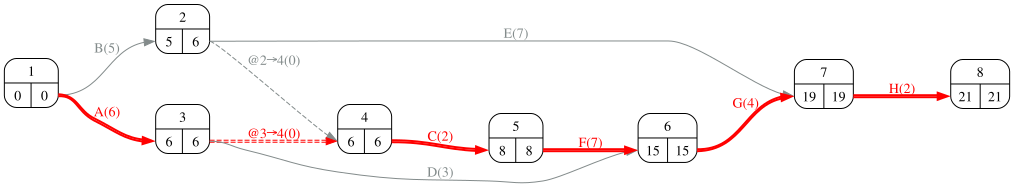

In [9]:
#| fig-cap: "Grafo PERT del proyecto"
#| label: fig-pert
proyecto.display_pert_pasos(datos_proyecto['duration'])

## Apartado 1

In [10]:
display(Markdown(pregunta_1))

1. (A) Calcule el coste de cada oferta puesta en obra (precio, transporte y, en la importada, los certificados CBAM con el cálculo simplificado del enunciado) y las emisiones de cada una (implícitas más transporte).  

In [11]:
#| tbl-cap: "Coste puesto en obra y emisiones de cada oferta"
#| label: tbl-ofertasCalculo
o = ofertas.copy()
o['acero (k€)'] = toneladas * o['precio (€/t)'] / 1000
o['transporte (k€)'] = toneladas * (o['km por carretera'] * coste_camion + o['km por mar'] * coste_barco) / 1000
o['CBAM (k€)'] = [0.0, toneladas * o.loc['acería importada', 'emisiones implícitas (t CO2/t)'] * precio_ets / 1000]
o['coste en obra (k€)'] = o['acero (k€)'] + o['transporte (k€)'] + o['CBAM (k€)']
o['emisiones implícitas (t)'] = toneladas * o['emisiones implícitas (t CO2/t)']
o['emisiones del transporte (t)'] = toneladas * (o['km por carretera'] * factor_camion + o['km por mar'] * factor_barco) / 1000
o['emisiones (t CO₂)'] = o['emisiones implícitas (t)'] + o['emisiones del transporte (t)']
display(o.iloc[:, 5:].round(2).T)
Markdown(f'''Sin el CBAM la importada es {o.iloc[0, 8] - (o.iloc[1, 5] + o.iloc[1, 6]):.1f} k€ más barata; con los certificados ({o.iloc[1, 7]:.1f} k€) ''' + ('sigue siendo' if o.iloc[1, 8] < o.iloc[0, 8] else 'pasa a ser') + f''' {abs(o.iloc[0, 8] - o.iloc[1, 8]):.1f} k€ ''' + ('más barata' if o.iloc[1, 8] < o.iloc[0, 8] else 'más cara') + f'''. Emite {o.iloc[1, 11] - o.iloc[0, 11]:.0f} t más.''')

oferta,acería europea,acería importada
acero (k€),239.40,180.60
transporte (k€),7.56,60.48
CBAM (k€),0.00,33.77
coste en obra (k€),246.96,274.85
emisiones implícitas (t),294.00,504.00
emisiones del transporte (t),6.30,46.20
emisiones (t CO₂),300.30,550.20


Sin el CBAM la importada es 5.9 k€ más barata; con los certificados (33.8 k€) pasa a ser 27.9 k€ más cara. Emite 250 t más.

## Apartado 2

In [12]:
display(Markdown(pregunta_2))

2. (A) Calcule el efecto en el plazo de las 2 semanas de entrega: holgura total de F, retraso del proyecto y penalidad. Obtenga el coste total de cada oferta con el retraso y, además, con las emisiones al precio sombra.  

In [13]:
holgura = int(calendario.loc[actividad_acero, 'H_total'])
duraciones_importado = datos_proyecto['duration'].copy(); duraciones_importado[actividad_acero] += ofertas.loc['acería importada', 'semanas de entrega']
duracion_importado = int(proyecto.duration(duraciones_importado))
retraso = duracion_importado - duracion
o['retraso (semanas)'] = [0, retraso]
o['penalidad (k€)'] = o['retraso (semanas)'] * penalidad
o['coste total (k€)'] = o['coste en obra (k€)'] + o['penalidad (k€)']
o['coste total al precio sombra (k€)'] = o['coste total (k€)'] + o['emisiones (t CO₂)'] * precio_sombra / 1000
display(o[['coste en obra (k€)', 'retraso (semanas)', 'penalidad (k€)', 'coste total (k€)', 'emisiones (t CO₂)', 'coste total al precio sombra (k€)']].round(1).T)
Markdown(f'''{actividad_acero} tiene {holgura} semana(s) de holgura total: las {int(ofertas.loc["acería importada", "semanas de entrega"])} de entrega retrasan el proyecto **{retraso}** semana(s) ({retraso * penalidad} k€). Coste total: europea **{o.iloc[0, 14]:.1f} k€**, importada **{o.iloc[1, 14]:.1f} k€**; al precio sombra, {o.iloc[0, 15]:.1f} frente a {o.iloc[1, 15]:.1f} k€.''')

oferta,acería europea,acería importada
coste en obra (k€),247.0,274.8
retraso (semanas),0.0,2.0
penalidad (k€),0.0,24.0
coste total (k€),247.0,298.8
emisiones (t CO₂),300.3,550.2
coste total al precio sombra (k€),292.0,381.4


F tiene 0 semana(s) de holgura total: las 2 de entrega retrasan el proyecto **2** semana(s) (24 k€). Coste total: europea **247.0 k€**, importada **298.8 k€**; al precio sombra, 292.0 frente a 381.4 k€.

## Apartado 3

In [14]:
display(Markdown(pregunta_3))

3. (B) Según los criterios y la norma de referencia, ¿qué oferta se elige? ¿Es cierto que las emisiones de la acería «no son nuestras»? ¿Está la importación exenta del CBAM?  

**S2.** La comparación correcta es el coste total puesto en obra con el ajuste en frontera, el transporte, el retraso y la externalidad al precio sombra: la **acería europea** (292.0 k€ frente a 381.4). El 25% del director de compras es la primera columna de una tabla de seis. **S6.** Las emisiones implícitas del acero comprado son **alcance 3** del proyecto: 504 t frente a 294; ser de la acería no las saca del inventario, y el CBAM existe precisamente para que paguen el mismo carbono que las europeas. **Norma.** La importación (210 t) supera las 50 t anuales del umbral de minimis: la empresa, como declarante, compra los certificados (33.8 k€ con el cálculo simplificado; la liquidación real descuenta la asignación gratuita que aún reciben las acerías europeas y el precio del carbono pagado en origen). Y las 2 semanas no «las absorbe la obra»: las absorbe la holgura de F (0 semana(s)), y lo que sobra va al plazo.

In [15]:
preguntas_test = [
    ('Las emisiones implícitas del acero comprado por el proyecto son, en su inventario…', ['alcance 3', 'alcance 1', 'alcance 2', 'de la acería, no del proyecto'],
     'S6: materiales comprados.'),
    ('Un importador de 120 t de acero al año, con el CBAM en su periodo definitivo…', ['debe adquirir certificados por las emisiones implícitas (supera las 50 t de minimis)', 'está exento', 'sólo declara, sin pagar', 'paga el IVA del carbono'],
     'Reglamento (UE) 2023/956 modificado por el 2025/2083: umbral de 50 t por importador y año.'),
    ('Un retraso de entrega de d semanas en una actividad con holgura total H retrasa el proyecto…', ['máx(0, d − H) semanas', 'd semanas', 'H semanas', 'nada si la actividad no es inicial'],
     'Lección 05: la holgura total es lo que puede retrasarse sin mover el fin.'),
]
import os
def a_gift(preguntas_test, titulo, semilla=1):
    r = np.random.default_rng(semilla)
    lineas = [f'$CATEGORY: {titulo}', '']
    for i, (q, ops, fb) in enumerate(preguntas_test, 1):
        correcta = ops[0]
        todas = [ops[j] for j in r.permutation(len(ops))]
        cuerpo = ' '.join((f'={v}' if v == correcta else f'~{v}') for v in todas)
        lineas.append(f'::{titulo} P{i}::{q} {{{cuerpo} ####{fb}}}')
        lineas.append('')
    return '\n'.join(lineas)
gift = a_gift(preguntas_test, 'Sostenibilidad 20 — acero importado')
os.makedirs(os.path.expanduser('~/temp'), exist_ok=True)
with open(os.path.expanduser('~/temp/cuestionario_sostenibilidad.gift'), 'w', encoding='utf8') as f:
    f.write(gift)
from pmule import muestra_test
muestra_test(preguntas_test)

$CATEGORY: Sostenibilidad 20 — acero importado

::Sostenibilidad 20 — acero importado P1::Las emisiones implícitas del acero comprado por el proyecto son, en su inventario… {=alcance 3 ~alcance 1 ~alcance 2 ~de la acería, no del proyecto ####S6: materiales comprados.}

::Sostenibilidad 20 — acero importado P2::Un importador de 120 t de acero al año, con el CBAM en su periodo definitivo… {~paga el IVA del carbono =debe adquirir certificados por las emisiones implícitas (supera las 50 t de minimis) ~sólo declara, sin pagar ~está exento ####Reglamento (UE) 2023/956 modificado por el 2025/2083: umbral de 50 t por importador y año.}

::Sostenibilidad 20 — acero importado P3::Un retraso de entrega de d semanas en una actividad con holgura total H retrasa el proyecto… {~nada si la actividad no es inicial =máx(0, d − H) semanas ~d semanas ~H semanas ####Lección 05: la holgura total es lo que puede retrasarse sin mover el fin.}



## Apartado 4

In [16]:
display(Markdown(pregunta_4))

4. (C) ¿Qué propone al director de compras? Aplique la rúbrica de la lección.  

La pregunta del bloque C es abierta: no tiene una respuesta única y se evalúa el **procedimiento**: (1) identificar a todos los afectados, incluidos los que no están en la mesa (la comunidad, los trabajadores de la cadena, quien opere o desmantele lo construido, las generaciones siguientes) y qué pierde o gana cada uno con las cifras del bloque A; (2) formular al menos dos alternativas además de la propuesta, situándolas en la pirámide (compensar, restaurar, minimizar, evitar); (3) someter cada alternativa a tres pruebas —legalidad (¿cumple la norma?), publicidad (¿la defendería ante el inspector, el cliente o la prensa?) y ciclo de vida (¿quién paga el impacto y cuándo?)—; (4) decidir y redactar la comunicación con las cifras. Una respuesta que sólo opina, sin cifras ni alternativas, no supera la rúbrica.

Al director de compras: la tabla del apartado 2 entera, no la primera columna; si se quiere negociar, negociar con la acería europea con esa tabla en la mano, o pedir a la importada la entrega en plazo y el certificado de emisiones verificadas (si son menores que el valor por defecto, el CBAM baja). Prueba del ciclo de vida: la diferencia de 250 t no desaparece por facturarla otro; prueba de publicidad: ¿explicaría al cliente las 2 semanas de retraso por un acero que, puesto en obra, salía más caro?